# Análisis de datos: Alcancía inteligente de colones

**Pregunta:** ¿cuánto efectivo acumula una persona sin darse cuenta, cuándo lo ahorra y qué tan rápido llega a su meta? ¿Se pueden detectar movimientos anómalos?

La pregunta sale del problema que motiva el proyecto: las monedas del vuelto se acumulan sin que nadie sepa cuánto suman. Cada depósito, moneda devuelta, apertura y retiro queda guardado en Supabase; este cuaderno los descarga (`descargar_eventos.py`) y responde por partes:

1. **¿Cuánto se acumula y qué lo explica?** Valor frente a cantidad por denominación.
2. **¿Cuándo se ahorra?** Día de la semana y hora.
3. **¿Qué tan rápido se llega a la meta?** Ritmo de ahorro y simulación Monte Carlo de la fecha.
4. **¿Hay anomalías?** Reglas y un modelo de aprendizaje automático (Isolation Forest).
5. **¿Qué tan bien funciona el monedero?** Tasa de monedas devueltas.

En Google Colab: sube `eventos.csv` y `alcancias.csv` a una carpeta `datos/` y ejecuta todo.

In [1]:
# Fuente de los datos: "real" usa datos/eventos.csv; "simulado" genera datos de ejemplo
# para ver el método funcionando. Los datos simulados NO son resultados del proyecto.
FUENTE = "real"

In [2]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

ZONA = "America/Costa_Rica"
MONEDAS = [10, 25, 50, 100, 500]
BILLETES = [1000, 2000, 5000, 10000, 20000]
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
DIAS_PLURAL = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábados", "domingos"]
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
VERDE, ORO, GRIS = "#14532d", "#c8972b", "#9ca3af"
ROJO = "#b3261e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
colones = lambda x: f"₡{x:,.0f}".replace(",", " ")


def fechas_en_espanol(eje):
    eje.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=7))
    eje.xaxis.set_major_formatter(lambda valor, _: (lambda d: f"{d.day} {MESES[d.month - 1]}")(mdates.num2date(valor)))

## 1. Carga y calidad de los datos

In [3]:
def datos_simulados(semilla=7, semanas=8):
    # Cinco personas con hábitos distintos y dos anomalías sembradas a propósito
    azar = np.random.default_rng(semilla)
    hoy = pd.Timestamp.now(tz=ZONA).normalize()
    perfiles = {  # (monedas por día entre semana, en fin de semana, hora típica, meta)
        "usuario_1": (1.2, 3.0, 19, 25000), "usuario_2": (0.6, 1.0, 8, 15000),
        "usuario_3": (2.0, 2.0, 13, 40000), "usuario_4": (0.3, 2.5, 21, 20000),
        "usuario_5": (1.0, 1.0, 17, 10000),
    }
    pesos = np.array([3, 2, 3, 4, 1.5, 0.6, 0.3, 0.1])
    valores = MONEDAS + [1000, 2000, 5000]
    filas, metas = [], []
    for usuario, (semana, finde, hora, meta) in perfiles.items():
        metas.append({"usuario": usuario, "meta_colones": meta, "creada_en": hoy - pd.Timedelta(weeks=semanas)})
        for atras in range(semanas * 7, -1, -1):
            dia = hoy - pd.Timedelta(days=atras)
            for _ in range(azar.poisson(finde if dia.dayofweek >= 4 else semana)):
                momento = dia + pd.Timedelta(hours=int(np.clip(azar.normal(hora, 1.5), 0, 23)), minutes=int(azar.integers(60)))
                if azar.random() < 0.04:
                    filas.append({"usuario": usuario, "tipo": "rechazo", "denominacion": np.nan, "cantidad": 1, "origen": "dispositivo", "ocurrido_en": momento})
                else:
                    filas.append({"usuario": usuario, "tipo": "deposito", "denominacion": azar.choice(valores, p=pesos / pesos.sum()), "cantidad": 1, "origen": "dispositivo", "ocurrido_en": momento})
    # Anomalías sembradas: un retiro grande y una apertura sin retiro registrado
    filas.append({"usuario": "usuario_3", "tipo": "retiro", "denominacion": 500, "cantidad": 12, "origen": "app", "ocurrido_en": hoy - pd.Timedelta(days=10, hours=-14)})
    filas.append({"usuario": "usuario_3", "tipo": "apertura", "denominacion": np.nan, "cantidad": 1, "origen": "dispositivo", "ocurrido_en": hoy - pd.Timedelta(days=10, hours=-14, seconds=-30)})
    filas.append({"usuario": "usuario_2", "tipo": "apertura", "denominacion": np.nan, "cantidad": 1, "origen": "dispositivo", "ocurrido_en": hoy - pd.Timedelta(days=4, hours=-3)})
    return pd.DataFrame(filas), pd.DataFrame(metas)


if FUENTE == "real":
    eventos = pd.read_csv(Path("datos") / "eventos.csv")
    alcancias = pd.read_csv(Path("datos") / "alcancias.csv")
else:
    eventos, alcancias = datos_simulados()

eventos["ocurrido_en"] = pd.to_datetime(eventos["ocurrido_en"], utc=True, format="ISO8601").dt.tz_convert(ZONA)
eventos["denominacion"] = pd.to_numeric(eventos["denominacion"])
eventos["colones"] = (eventos["denominacion"] * eventos["cantidad"]).fillna(0)
eventos["signo"] = eventos["tipo"].map({"deposito": 1, "retiro": -1}).fillna(0)
eventos["neto"] = eventos["colones"] * eventos["signo"]
eventos["dia"] = eventos["ocurrido_en"].dt.normalize()
eventos = eventos.sort_values("ocurrido_en").reset_index(drop=True)

print(f"Fuente: {FUENTE.upper()}")
alcancias_texto = lambda n: f"{n} alcancía" if n == 1 else f"{n} alcancías"
print(f"{len(eventos)} eventos de {alcancias_texto(eventos['usuario'].nunique())}, "
      f"del {eventos['ocurrido_en'].min():%d/%m/%Y} al {eventos['ocurrido_en'].max():%d/%m/%Y} "
      f"({eventos['dia'].nunique()} días con actividad)")
display(eventos.groupby("tipo").agg(eventos=("tipo", "size"), colones=("colones", "sum")))

Fuente: REAL
21 eventos de 1 alcancía, del 30/10/2026 al 24/11/2026 (2 días con actividad)


,eventos,colones
tipo,,
apertura,1,0.0
deposito,16,13605.0
rechazo,1,0.0
retiro,3,11100.0


## 2. ¿Cuánto se acumula y qué lo explica?

El peso de la alcancía no dice cuánto hay. Este gráfico compara qué parte de las **monedas y billetes** aporta cada denominación frente a qué parte del **dinero** aporta.

,meta_colones,saldo,avance_meta
usuario,,,
usuario_1,₡10 000,₡2 505,25%


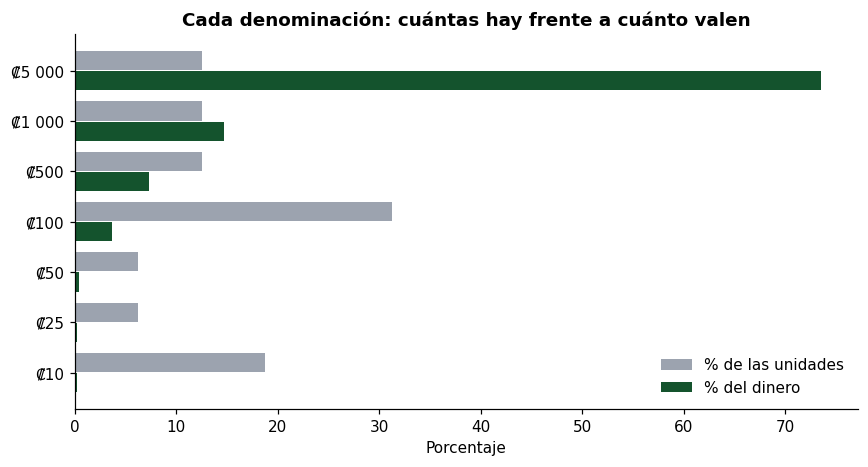

La denominación que más pesa en el dinero es ₡5 000: 12 % de las unidades, pero 74 % del dinero.


In [4]:
depositos = eventos[eventos["tipo"] == "deposito"]
saldo = eventos.groupby("usuario")["neto"].sum()
resumen = (alcancias.set_index("usuario")[["meta_colones"]]
           .join(saldo.rename("saldo")).fillna({"saldo": 0}))
resumen["avance_meta"] = (resumen["saldo"] / resumen["meta_colones"]).map("{:.0%}".format)
display(resumen.style.format({"meta_colones": colones, "saldo": colones}))

por_denominacion = depositos.groupby("denominacion").agg(cantidad=("cantidad", "sum"), colones=("colones", "sum"))
reparto = pd.DataFrame({
    "% de las unidades": por_denominacion["cantidad"] / por_denominacion["cantidad"].sum() * 100,
    "% del dinero": por_denominacion["colones"] / por_denominacion["colones"].sum() * 100,
}).sort_index()

fig, eje = plt.subplots(figsize=(8, 0.45 * len(reparto) + 1.2))
posiciones = np.arange(len(reparto))
eje.barh(posiciones + 0.2, reparto["% de las unidades"], height=0.38, color=GRIS, label="% de las unidades")
eje.barh(posiciones - 0.2, reparto["% del dinero"], height=0.38, color=VERDE, label="% del dinero")
eje.set_yticks(posiciones, [colones(v) for v in reparto.index])
eje.set_xlabel("Porcentaje")
eje.set_title("Cada denominación: cuántas hay frente a cuánto valen")
eje.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

mayor = reparto["% del dinero"].idxmax()
print(f"La denominación que más pesa en el dinero es {colones(mayor)}: "
      f"{reparto.loc[mayor, '% de las unidades']:.0f} % de las unidades, pero {reparto.loc[mayor, '% del dinero']:.0f} % del dinero.")

## 3. ¿Cuándo se ahorra?

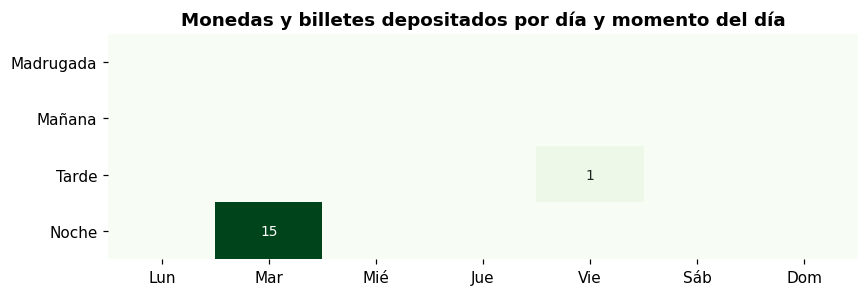

Se ahorra más los martes y en la noche.


In [5]:
mapa = (depositos.assign(dia_semana=depositos["ocurrido_en"].dt.dayofweek,
                         franja=pd.cut(depositos["ocurrido_en"].dt.hour, [0, 6, 12, 18, 24], right=False,
                                       labels=["Madrugada", "Mañana", "Tarde", "Noche"]))
        .pivot_table(index="franja", columns="dia_semana", values="cantidad", aggfunc="sum", observed=False)
        .reindex(columns=range(7)).fillna(0))

fig, eje = plt.subplots(figsize=(8, 2.8))
imagen = eje.imshow(mapa.values, cmap="Greens", aspect="auto")
eje.set_xticks(range(7), DIAS); eje.set_yticks(range(len(mapa.index)), mapa.index)
for (fila, columna), valor in np.ndenumerate(mapa.values):
    if valor:
        eje.text(columna, fila, f"{valor:.0f}", ha="center", va="center",
                 color="white" if valor > mapa.values.max() * 0.6 else "#1c2620", fontsize=9)
eje.set_title("Monedas y billetes depositados por día y momento del día")
for lado in eje.spines.values(): lado.set_visible(False)
plt.tight_layout(); plt.show()

dia_pico = int(mapa.sum().idxmax())
franja_pico = mapa.sum(axis=1).idxmax()
print(f"Se ahorra más los {DIAS_PLURAL[dia_pico]} y en la {franja_pico.lower()}.")

## 4. ¿Qué tan rápido se llega a la meta?

Se toma el ahorro neto de cada día de las últimas 4 semanas (depósitos menos retiros, contando los días sin ahorro como cero) y se simulan 5000 futuros posibles sorteando esos días al azar (**Monte Carlo**). Así la respuesta no es una sola fecha sino un rango: la fecha más probable y un intervalo del 80 %.

usuario_1: saldo ₡2 505 de ₡10 000, ritmo ₡674 por semana → sin datos suficientes para proyectar


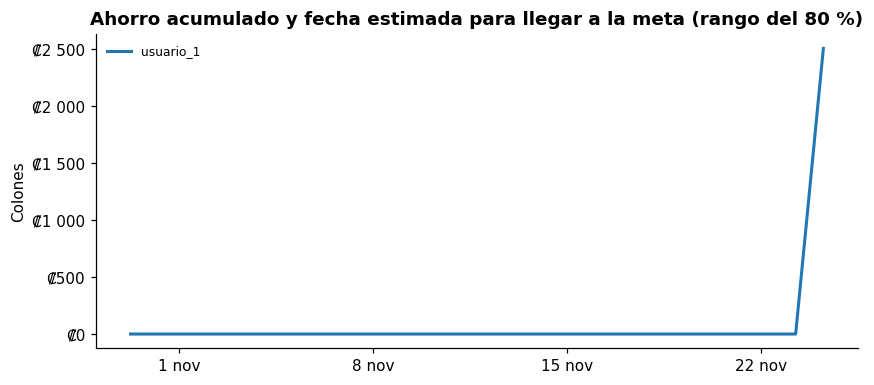

In [6]:
def proyectar(usuario, simulaciones=5000, ventana=28, maximo_dias=1095, semilla=0):
    propios = eventos[eventos["usuario"] == usuario]
    hoy = pd.Timestamp.now(tz=ZONA).normalize()
    diario = propios.groupby("dia")["neto"].sum().reindex(pd.date_range(propios["dia"].min(), hoy, freq="D"), fill_value=0)
    meta = alcancias.set_index("usuario").loc[usuario, "meta_colones"]
    saldo_actual = diario.sum()
    recientes = diario.iloc[-ventana:].to_numpy()
    resultado = {"usuario": usuario, "saldo": saldo_actual, "meta": meta, "dias_con_datos": len(recientes),
                 "ritmo_semanal": recientes.mean() * 7, "serie": diario.cumsum()}
    if saldo_actual >= meta:
        resultado["estado"] = "meta alcanzada"
    elif (recientes != 0).sum() < 5 or recientes.mean() <= 0:
        # Con menos de 5 días con movimientos, cualquier fecha sería inventada
        resultado["estado"] = "sin datos suficientes para proyectar"
    else:
        azar = np.random.default_rng(semilla)
        caminos = azar.choice(recientes, size=(simulaciones, maximo_dias)).cumsum(axis=1)
        llega = caminos >= meta - saldo_actual
        dias = np.where(llega.any(axis=1), llega.argmax(axis=1) + 1, np.nan)
        p10, p50, p90 = np.nanpercentile(dias, [10, 50, 90])
        resultado.update(estado="proyectada", p10=hoy + pd.Timedelta(days=p10),
                         p50=hoy + pd.Timedelta(days=p50), p90=hoy + pd.Timedelta(days=p90))
    return resultado


proyecciones = [proyectar(u) for u in alcancias["usuario"]]
for p in proyecciones:
    texto = f"{p['usuario']}: saldo {colones(p['saldo'])} de {colones(p['meta'])}, ritmo {colones(p['ritmo_semanal'])} por semana → {p['estado']}"
    if p["estado"] == "proyectada":
        texto += f": cerca del {p['p50']:%d/%m/%Y} (80 %: entre el {p['p10']:%d/%m} y el {p['p90']:%d/%m})"
    print(texto)

fig, eje = plt.subplots(figsize=(8, 3.6))
for p in proyecciones:
    serie = p["serie"]
    linea, = eje.plot(serie.index, serie.values, lw=2, label=p["usuario"])
    if p["estado"] == "proyectada":
        eje.plot([serie.index[-1], p["p50"]], [serie.iloc[-1], p["meta"]], ls=":", lw=2, color=linea.get_color())
        # Rango del 80 % como segmento horizontal a la altura de la meta, y la fecha más probable como punto
        eje.plot([p["p10"], p["p90"]], [p["meta"], p["meta"]], lw=5, alpha=0.35, color=linea.get_color(), solid_capstyle="round")
        eje.plot(p["p50"], p["meta"], "o", ms=7, color=linea.get_color())
eje.set_title("Ahorro acumulado y fecha estimada para llegar a la meta (rango del 80 %)")
eje.set_ylabel("Colones"); eje.yaxis.set_major_formatter(lambda v, _: colones(v))
fechas_en_espanol(eje)
eje.legend(frameon=False, ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

## 5. ¿Hay movimientos anómalos?

Dos capas:

- **Reglas claras:** una apertura sin un retiro registrado cerca (alguien sacó dinero sin anotarlo) y retiros mucho mayores que lo normal.
- **Aprendizaje automático:** un **Isolation Forest** revisa cada día de cada alcancía (cuánto se depositó, cuánto se retiró, aperturas y devoluciones) y marca los días que se parecen poco al resto. No necesita ejemplos de fraude para aprender: aprende cómo es un día normal.

In [7]:
aperturas = eventos[eventos["tipo"] == "apertura"]
retiros = eventos[eventos["tipo"] == "retiro"]
sospechas = []
for _, apertura in aperturas.iterrows():
    cercanos = retiros[(retiros["usuario"] == apertura["usuario"])
                       & ((retiros["ocurrido_en"] - apertura["ocurrido_en"]).abs() <= pd.Timedelta(minutes=15))]
    if cercanos.empty:
        sospechas.append({"usuario": apertura["usuario"], "cuándo": apertura["ocurrido_en"], "motivo": "Apertura sin retiro registrado"})
if len(retiros) >= 5:
    limite = retiros["colones"].median() + 3 * (retiros["colones"].quantile(0.75) - retiros["colones"].quantile(0.25))
    for _, retiro in retiros[retiros["colones"] > limite].iterrows():
        sospechas.append({"usuario": retiro["usuario"], "cuándo": retiro["ocurrido_en"], "motivo": f"Retiro inusual de {colones(retiro['colones'])}"})
print("Reglas:")
display(pd.DataFrame(sospechas) if sospechas else "Ninguna apertura ni retiro fuera de lo normal.")

diario = (eventos.assign(deposito=eventos["colones"].where(eventos["tipo"] == "deposito", 0),
                         retiro=eventos["colones"].where(eventos["tipo"] == "retiro", 0),
                         apertura=(eventos["tipo"] == "apertura").astype(int),
                         rechazo=(eventos["tipo"] == "rechazo").astype(int))
          .groupby(["usuario", "dia"])[["deposito", "retiro", "apertura", "rechazo"]].sum().reset_index())

if len(diario) >= 20:
    columnas = ["deposito", "retiro", "apertura", "rechazo"]
    modelo = IsolationForest(n_estimators=300, contamination=0.03, random_state=0)
    diario["anomalo"] = modelo.fit_predict(StandardScaler().fit_transform(diario[columnas])) == -1
    diario["puntaje"] = -modelo.score_samples(StandardScaler().fit_transform(diario[columnas]))

    fig, eje = plt.subplots(figsize=(8, 3.2))
    normales, raros = diario[~diario["anomalo"]], diario[diario["anomalo"]]
    eje.scatter(normales["dia"], normales["deposito"] - normales["retiro"], s=14, color=GRIS, label="Día normal")
    eje.scatter(raros["dia"], raros["deposito"] - raros["retiro"], s=60, color=ROJO, label="Día anómalo")
    eje.axhline(0, color="#1c2620", lw=0.8)
    eje.set_title("Ahorro neto por día y alcancía: días que el modelo marca como anómalos")
    eje.yaxis.set_major_formatter(lambda v, _: colones(v)); eje.legend(frameon=False)
    fechas_en_espanol(eje)
    plt.tight_layout(); plt.show()
    print("Días anómalos según el Isolation Forest:")
    display(raros.sort_values("puntaje", ascending=False)[["usuario", "dia"] + columnas])
else:
    print(f"El modelo necesita al menos 20 días de actividad para aprender qué es normal; hay {len(diario)}.")

Reglas:


'Ninguna apertura ni retiro fuera de lo normal.'

El modelo necesita al menos 20 días de actividad para aprender qué es normal; hay 2.


## 6. ¿Qué tan bien reconoce la alcancía lo que entra?

In [8]:
del_dispositivo = eventos[eventos["origen"] == "dispositivo"]
aceptadas = del_dispositivo.loc[del_dispositivo["tipo"] == "deposito", "cantidad"].sum()
devueltas = (del_dispositivo["tipo"] == "rechazo").sum()
tasa = devueltas / (aceptadas + devueltas) if aceptadas + devueltas else float("nan")
print(f"Devueltas: {devueltas} de {aceptadas + devueltas} ({tasa:.1%}). "
      + ("Por encima del 5 %: conviene reentrenar el monedero." if tasa > 0.05 else "Dentro de lo esperado (≤ 5 %)."))

Devueltas: 1 de 17 (5.9%). Por encima del 5 %: conviene reentrenar el monedero.


## 7. Respuesta a la pregunta

In [9]:
print(f"Fuente de los datos: {FUENTE.upper()}\n")
print(f"• Cuánto: {alcancias_texto(eventos['usuario'].nunique())} con {colones(eventos['neto'].sum())} en total; "
      f"{colones(mayor)} es {reparto.loc[mayor, '% de las unidades']:.0f} % de las unidades pero {reparto.loc[mayor, '% del dinero']:.0f} % del dinero, "
      "por eso el peso no dice cuánto hay.")
print(f"• Cuándo: el ahorro se concentra los {DIAS_PLURAL[dia_pico]} y en la {franja_pico.lower()}.")
for p in proyecciones:
    if p["estado"] == "proyectada":
        print(f"• Meta de {p['usuario']}: cerca del {p['p50']:%d/%m/%Y} (80 %: {p['p10']:%d/%m} – {p['p90']:%d/%m}).")
    else:
        print(f"• Meta de {p['usuario']}: {p['estado']}.")
print(f"• Anomalías: {len(sospechas)} por reglas"
      + (f" y {int(diario['anomalo'].sum())} días según el Isolation Forest." if "anomalo" in diario else "; el modelo aún no tiene datos suficientes."))
print(f"• Monedero: {tasa:.1%} de devoluciones.")

Fuente de los datos: REAL

• Cuánto: 1 alcancía con ₡2 505 en total; ₡5 000 es 12 % de las unidades pero 74 % del dinero, por eso el peso no dice cuánto hay.
• Cuándo: el ahorro se concentra los martes y en la noche.
• Meta de usuario_1: sin datos suficientes para proyectar.
• Anomalías: 0 por reglas; el modelo aún no tiene datos suficientes.
• Monedero: 5.9% de devoluciones.


### Preguntas de IPM (completar con el estudio de usuarios)

- **¿Qué aprendieron del comportamiento de los usuarios?**
- **¿Qué cambiarían en la interfaz a partir de los datos?**
- **¿Qué variable fue la más relevante?** Candidata: la denominación, porque explica el valor mucho más que la cantidad de monedas.
- **¿Qué decisiones podrían automatizarse en una siguiente versión?** Candidatas: avisar al teléfono ante una apertura sin retiro, sugerir una meta según el ritmo real y recordar ahorrar en los días de menos actividad.